In [164]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import average_precision_score, log_loss
from sklearn.metrics import precision_recall_curve, roc_curve
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, accuracy_score, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras import layers, models
from tensorflow.keras.layers import GlobalMaxPooling1D, Flatten
from tensorflow.keras.layers import LSTM, Bidirectional, Dense, Input, Dropout, Flatten
from tensorflow.keras.layers import Attention, Concatenate, Multiply
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.utils import shuffle
from sklearn.utils.class_weight import compute_class_weight
from imblearn.over_sampling import SMOTE
from tensorflow.keras.regularizers import l2
from tensorflow.keras.layers import BatchNormalization
from tensorflow.keras.optimizers import RMSprop
from tensorflow.keras.layers import Conv1D, MaxPooling1D, GlobalAveragePooling1D

# data shtuff

In [2]:
#from google.colab import drive
#drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
train_audio = pd.read_csv("training_audio.csv")
train_video = pd.read_csv("training_video.csv")

dev_audio = pd.read_csv("dev_audio.csv")
dev_video = pd.read_csv("dev_video.csv")

test_audio = pd.read_csv("test_audio.csv")
test_video = pd.read_csv("test_video.csv")

In [3]:
train_audio_features = train_audio.drop(columns = ["Target"])
train_audio_target = train_audio['Target']
train_video_features = train_video.drop(columns=['Target'])
train_video_target = train_video['Target']

dev_audio_features = dev_audio.drop(columns=['Target'])
dev_audio_target = dev_audio['Target']
dev_video_features = dev_video.drop(columns=['Target'])
dev_video_target = dev_video['Target']

test_audio_features = test_audio.drop(columns=['Target'])
test_audio_target = test_audio['Target']
test_video_features = test_video.drop(columns=['Target'])
test_video_target = test_video['Target']

In [105]:
scaler_audio = MinMaxScaler().fit(pd.concat([train_audio_features, dev_audio_features, test_audio_features], axis = 0, ignore_index=True))
scaler_video = MinMaxScaler().fit(pd.concat([train_video_features, dev_video_features, test_video_features], axis = 0, ignore_index=True))


train_audio_features_scaled = scaler_audio.transform(train_audio_features)
train_video_features_scaled = scaler_video.transform(train_video_features)

dev_audio_features_scaled = scaler_audio.transform(dev_audio_features)
dev_video_features_scaled = scaler_video.transform(dev_video_features)

test_audio_features_scaled = scaler_audio.transform(test_audio_features)
test_video_features_scaled = scaler_video.transform(test_video_features)

In [106]:
sequence_length = 40

# Reshape data into sequences for LSTM
def reshape_for_lstm(features, target, seq_length):
    num_sequences = len(features) // seq_length
    X = features[:num_sequences * seq_length].reshape(-1, seq_length, features.shape[1])
    y = target.values[:num_sequences * seq_length].reshape(-1, seq_length)[:, 0]
    return X, y

In [107]:
X_train_audio, y_train = reshape_for_lstm(train_audio_features_scaled, train_audio_target, sequence_length)
X_train_video, temp1 = reshape_for_lstm(train_video_features_scaled, train_video_target, sequence_length)

X_dev_audio, y_dev = reshape_for_lstm(dev_audio_features_scaled, dev_audio_target, sequence_length)
X_dev_video, temp2 = reshape_for_lstm(dev_video_features_scaled, dev_video_target, sequence_length)

X_test_audio, y_test = reshape_for_lstm(test_audio_features_scaled, test_audio_target, sequence_length)
X_test_video, temp3 = reshape_for_lstm(test_video_features_scaled, test_video_target, sequence_length)

In [108]:
print(np.array_equal(y_train, temp1))
print(np.array_equal(y_dev, temp2))
print(np.array_equal(y_test, temp3))

True
True
True


In [118]:
# Flatten the data for SMOTE
X_train_audio_flat = X_train_audio.reshape(X_train_audio.shape[0], -1)
X_train_video_flat = X_train_video.reshape(X_train_video.shape[0], -1)

# Combine audio and video data into one feature set (optional)
X_train_combined_flat = np.concatenate([X_train_audio_flat, X_train_video_flat], axis=1)

# Apply SMOTE to the flattened data
smote = SMOTE(random_state=42)
X_train_combined_flat_resampled, y_train_resampled = smote.fit_resample(X_train_combined_flat, y_train)

# Split the combined data back into audio and video components (optional)
X_train_audio_flat_resampled = X_train_combined_flat_resampled[:, :X_train_audio_flat.shape[1]]
X_train_video_flat_resampled = X_train_combined_flat_resampled[:, X_train_audio_flat.shape[1]:]

# Reshape the data back to its original 3D form
X_train_audio_resampled = X_train_audio_flat_resampled.reshape(-1, sequence_length, X_train_audio.shape[2])
X_train_video_resampled = X_train_video_flat_resampled.reshape(-1, sequence_length, X_train_video.shape[2])

# Verify shapes
assert X_train_audio_resampled.shape[1:] == X_train_audio.shape[1:], "Audio data reshaping failed."
assert X_train_video_resampled.shape[1:] == X_train_video.shape[1:], "Video data reshaping failed."


# Evaluation

In [119]:
# Evaluate Model
def evaluate_model(y_true, y_pred, y_pred_probs, model_name):
    print(f"Evaluation for {model_name}")
    print("Confusion Matrix:")
    print(confusion_matrix(y_true, y_pred))
    print("Classification Report:")
    print(classification_report(y_true, y_pred))
    print("Accuracy:", accuracy_score(y_true, y_pred))
    print("Precision:", precision_score(y_true, y_pred))
    print("Recall:", recall_score(y_true, y_pred))
    print("F1 Score:", f1_score(y_true, y_pred))
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    specificity = tn / (tn + fp)
    print("Specificity:", specificity)
    print("ROC-AUC:", roc_auc_score(y_true, y_pred_probs))

In [120]:
# Plot Confusion Matrix
def plot_confusion_matrix(y_true, y_pred, model_name):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'Confusion Matrix for {model_name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

In [121]:
# Plotting the training and validation accuracy and loss
def plot_training_history(history, model_name):
    # Summarize history for accuracy
    plt.figure(figsize=(12, 5))
    #plt.rcParams.update({'font.size': 16})
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'])
    plt.plot(history.history['val_accuracy'])
    plt.title(f'Model Accuracy for {model_name}')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(['Training', 'Validation'], loc='lower right')

    # Summarize history for loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'])
    plt.plot(history.history['val_loss'])
    plt.title(f'Model Loss for {model_name}')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(['Training', 'Validation'], loc='upper right')

    plt.tight_layout()
    plt.show()

In [122]:
# Plot Precision-Recall Curve
def plot_roc_recall(model, X_test, y_test, model_name):
    # Plot ROC curve
    fpr, tpr, thresholds = roc_curve(y_test, model.predict(X_test))
    plt.plot(fpr, tpr, color='blue', lw=2, label='ROC curve')
    plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'ROC Curve for {model_name}')
    plt.legend(loc='lower right')
    plt.show()

    # Plot precision-recall curve
    precision, recall, thresholds = precision_recall_curve(y_test, model.predict(X_test))
    plt.plot(recall, precision, color='blue', lw=2, label='Precision-Recall curve')
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title(f'Precision-Recall Curve for {model_name}')
    plt.legend(loc='lower left')
    plt.show()

# model

In [180]:
def build_bilstm_attention_branch(input_shape, lstm_units=32, dropout_rate=0.5, l2_reg=0.01):
    input_layer = Input(shape=input_shape)

    # BiLSTM Layer
    #bilstm = Bidirectional(LSTM(32, return_sequences=True))(input_layer)
    bilstm = Bidirectional(LSTM(lstm_units, return_sequences=True, kernel_regularizer=l2(l2_reg)))(input_layer)
    bilstm = BatchNormalization()(bilstm)
    # attention
    attention = Attention()([bilstm, bilstm])
    combined = Concatenate()([bilstm, attention])
    pooling = GlobalMaxPooling1D()(combined)

    return input_layer, pooling

In [181]:
# Define input shapes
audio_input_shape = (sequence_length, X_train_audio.shape[2])
video_input_shape = (sequence_length, X_train_video.shape[2])

In [182]:
audio_input, audio_branch_output = build_bilstm_attention_branch(audio_input_shape, lstm_units=64, dropout_rate=0.5, l2_reg=0.001)
video_input, video_branch_output = build_bilstm_attention_branch(video_input_shape, lstm_units=64, dropout_rate=0.5, l2_reg=0.001)


In [183]:
merged = Concatenate()([audio_branch_output, video_branch_output])
dense = Dense(32, activation='relu', kernel_regularizer=l2(0.001))(merged)
dropout = Dropout(0.7)(dense)

output_layer = Dense(1, activation='sigmoid')(dropout)

In [184]:
multimodal_model = Model(inputs=[audio_input, video_input], outputs=output_layer)
#multimodal_model.compile(optimizer=RMSprop(learning_rate=1e-3), loss='binary_crossentropy', metrics=['accuracy'])
multimodal_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

In [185]:
# Summary of the model
multimodal_model.summary()

Model: "functional_16"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_34      │ (None, 40, 78)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_35      │ (None, 40, 378)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_34    │ (None, 40, 128)   │     73,216 │ input_layer_34[0… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_35    │ (None, 40, 128)   │    226,816 │ input_layer_35[0… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 40, 128)   │        512 │ bidirectional_34… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 40, 128)   │        512 │ bidirectional_35… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention_34        │ (None, 40, 128)   │          0 │ batch_normalizat… │
│ (Attention)         │                   │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention_35        │ (None, 40, 128)   │          0 │ batch_normalizat… │
│ (Attention)         │                   │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_50      │ (None, 40, 256)   │          0 │ batch_normalizat… │
│ (Concatenate)       │                   │            │ attention_34[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_51      │ (None, 40, 256)   │          0 │ batch_normalizat… │
│ (Concatenate)       │                   │            │ attention_35[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 256)       │          0 │ concatenate_50[0… │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 256)       │          0 │ concatenate_51[0… │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_52      │ (None, 512)       │          0 │ global_max_pooli… │
│ (Concatenate)       │                   │            │ global_max_pooli… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_28 (Dense)    │ (None, 32)        │     16,416 │ concatenate_52[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_14          │ (None, 32)        │          0 │ dense_28[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_29 (Dense)    │ (None, 1)         │         33 │ dropout_14[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 317,505 (1.21 MB)

 Trainable params: 316,993 (1.21 MB)

 Non-trainable params: 512 (2.00 KB)

In [186]:
early_stopping = tf.keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)
lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1)
class_weights = {0: 1.0, 1: len(y_train) / np.sum(y_train)}

In [187]:
# Train the model with training data and validate on dev data
history = multimodal_model.fit(
    [X_train_audio_resampled, X_train_video_resampled], y_train_resampled,
    epochs=10, batch_size=64,
    validation_data = ([X_test_audio, X_test_video], y_test)
    #validation_split = 0.2
    #validation_data=([X_dev_audio, X_dev_video], y_dev),
    #callbacks=[lr_scheduler],
    #class_weight=class_weights
)

Epoch 1/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 45s 172ms/step - accuracy: 0.5663 - loss: 1.4844 - val_accuracy: 0.7017 - val_loss: 1.0906
Epoch 2/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 29s 164ms/step - accuracy: 0.6961 - loss: 0.9088 - val_accuracy: 0.3591 - val_loss: 1.3241
Epoch 3/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 28s 156ms/step - accuracy: 0.7625 - loss: 0.6504 - val_accuracy: 0.3728 - val_loss: 1.3637
Epoch 4/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 32s 181ms/step - accuracy: 0.8283 - loss: 0.5295 - val_accuracy: 0.4857 - val_loss: 2.1164
Epoch 5/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 40s 223ms/step - accuracy: 0.8893 - loss: 0.4005 - val_accuracy: 0.6919 - val_loss: 2.0736
Epoch 6/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 26s 145ms/step - accuracy: 0.9229 - loss: 0.3437 - val_accuracy: 0.6902 - val_loss: 1.6461
Epoch 7/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 24s 138ms/step - accuracy: 0.9249 - loss: 0.3121 - val_accuracy: 0.5891 - val_loss: 2.7225
Epoch 8/10
177/177 ━━━━━━━━━━━━━━━━━━━━ 24s 136ms/step - accuracy: 0.9367 - loss: 0

In [188]:
# Evaluate the model on the test data
y_pred_probs = multimodal_model.predict([X_test_audio, X_test_video])
y_pred = (y_pred_probs > 0.5).astype(int)

112/112 ━━━━━━━━━━━━━━━━━━━━ 7s 49ms/step


In [ ]:
from tensorflow.keras.models import save_model

# Save the trained model to a file
model_path = "multimodal_bilstm_attention_model_official_split.h5"
multimodal_model.save(model_path)
print(f"Model saved to {model_path}")

In [ ]:
import pickle

# Assuming `history` is the variable containing your training history
history_path = "training_history_official_split.pkl"

# Save the history
with open(history_path, 'wb') as file:
    pickle.dump(history.history, file)

print(f"Training history saved to {history_path}")

# results

In [189]:
# Calculate metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_probs)
conf_matrix = confusion_matrix(y_test, y_pred)
specificity = conf_matrix[0, 0] / (conf_matrix[0, 0] + conf_matrix[0, 1])

# Print the metrics
print(f'Accuracy: {accuracy}')
print(f'Precision: {precision}')
print(f'Recall: {recall}')
print(f'F1 Score: {f1}')
print(f'ROC AUC Score: {roc_auc}')
print(f'Specificity: {specificity}')
print('Confusion Matrix:')
print(conf_matrix)
print('Classification Report:')
print(classification_report(y_test, y_pred))

Accuracy: 0.5781512605042017
Precision: 0.3252336448598131
Recall: 0.5523809523809524
F1 Score: 0.40941176470588236
ROC AUC Score: 0.6002146636432351
Specificity: 0.5874285714285714
Confusion Matrix:
[[1542 1083]
 [ 423  522]]
Classification Report:


              precision    recall  f1-score   support

           0       0.78      0.59      0.67      2625
           1       0.33      0.55      0.41       945

    accuracy                           0.58      3570
   macro avg       0.55      0.57      0.54      3570
weighted avg       0.66      0.58      0.60      3570



In [190]:
# Evaluate the model
evaluate_model(y_test, y_pred, y_pred_probs, "Multimodal BiLSTM + Attention Model")

Evaluation for Multimodal BiLSTM + Attention Model
Confusion Matrix:
[[1542 1083]
 [ 423  522]]
Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.59      0.67      2625
           1       0.33      0.55      0.41       945

    accuracy                           0.58      3570
   macro avg       0.55      0.57      0.54      3570
weighted avg       0.66      0.58      0.60      3570

Accuracy: 0.5781512605042017
Precision: 0.3252336448598131
Recall: 0.5523809523809524
F1 Score: 0.40941176470588236
Specificity: 0.5874285714285714
ROC-AUC: 0.6002146636432351


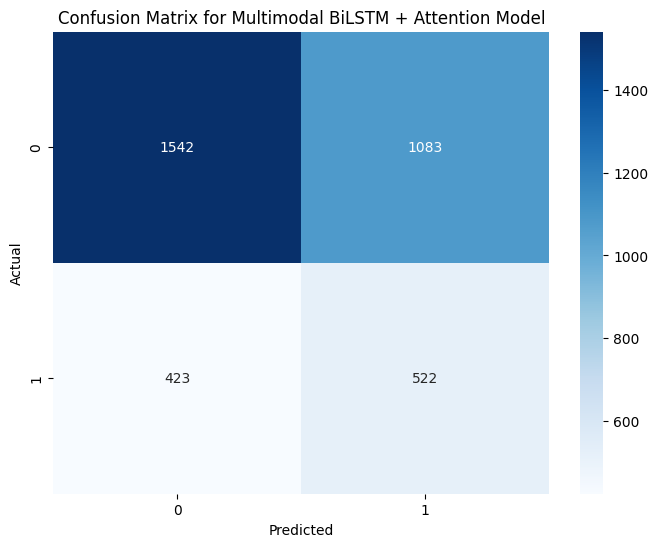

In [191]:
plot_confusion_matrix(y_test, y_pred, "Multimodal BiLSTM + Attention Model")

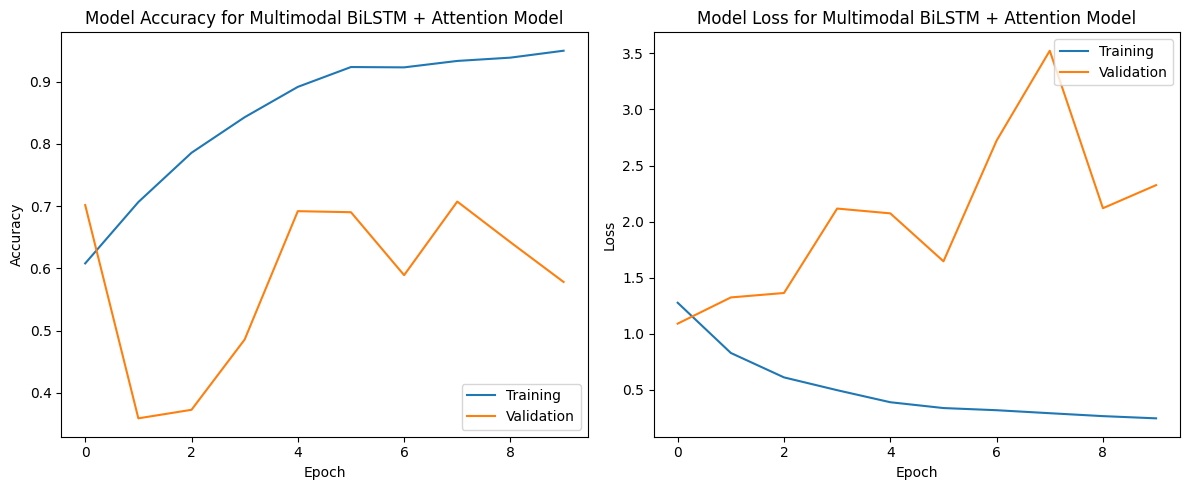

In [192]:
plot_training_history(history, "Multimodal BiLSTM + Attention Model")

112/112 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step


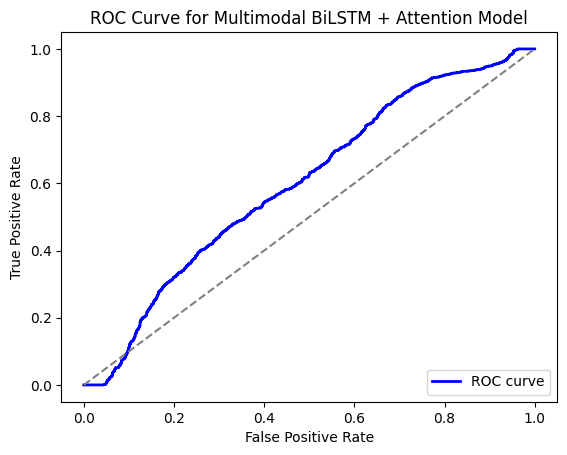

112/112 ━━━━━━━━━━━━━━━━━━━━ 5s 43ms/step


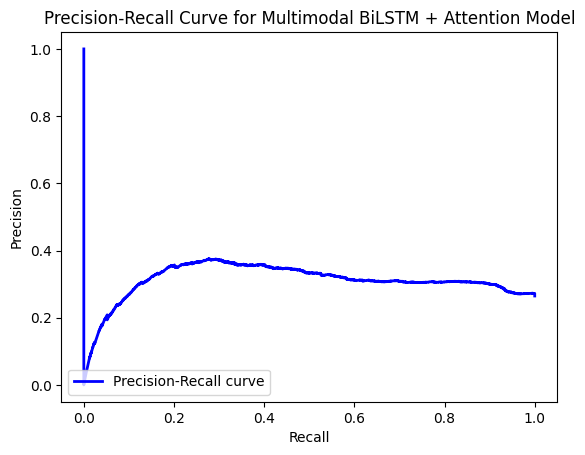

In [193]:
plot_roc_recall(multimodal_model, [X_test_audio, X_test_video], y_test, "Multimodal BiLSTM + Attention Model")